# Pedro Domitti de Carvalho | RA: 21005320

In [1]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('../data/beer.xlsx')
df.drop('Data', axis=1, inplace=True)

df.head()

,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),Final de Semana,Consumo de cerveja (litros)
0,27.30,23.9,32.5,0.0,0,25461
1,27.02,24.5,33.5,0.0,0,28972
2,24.82,22.4,29.9,0.0,1,30814
3,23.98,21.5,28.6,1.2,1,29799
4,23.82,21.0,28.3,0.0,0,28900


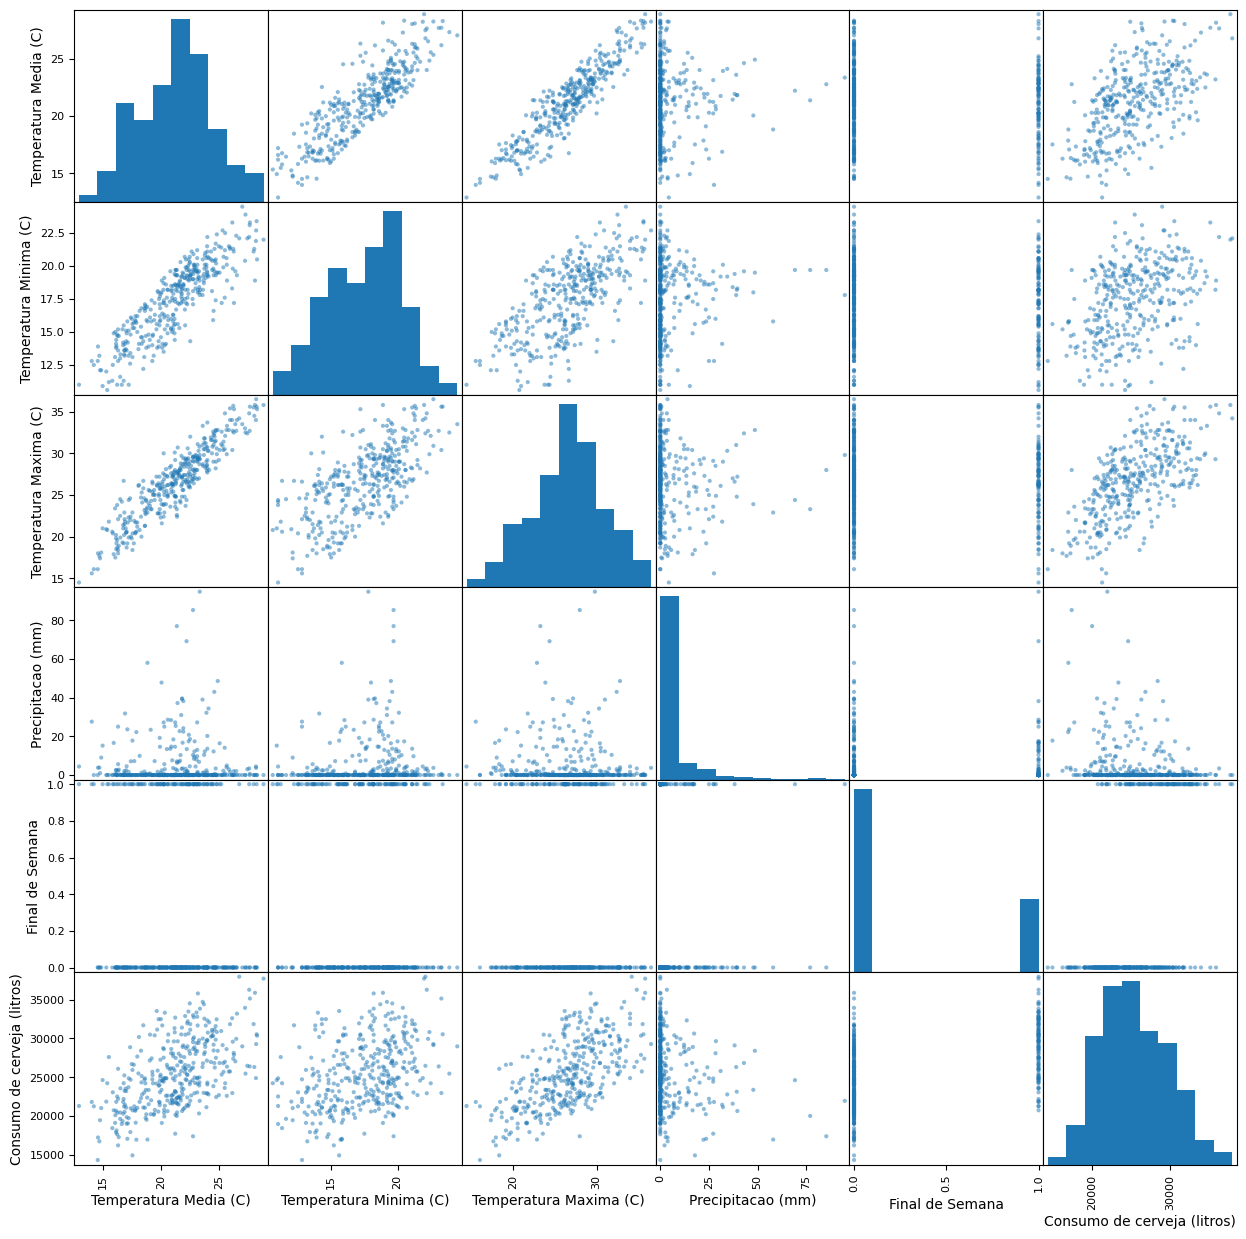

In [3]:
pd.plotting.scatter_matrix(df, figsize=(15, 15))
plt.show()

In [4]:
df.corr()

,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),Final de Semana,Consumo de cerveja (litros)
Temperatura Media (C),1.000000,0.862752,0.922513,0.024416,-0.050803,0.574615
Temperatura Minima (C),0.862752,1.000000,0.672929,0.098625,-0.059534,0.392509
Temperatura Maxima (C),0.922513,0.672929,1.000000,-0.049305,-0.040258,0.642672
Precipitacao (mm),0.024416,0.098625,-0.049305,1.000000,0.001587,-0.193784
Final de Semana,-0.050803,-0.059534,-0.040258,0.001587,1.000000,0.505981
Consumo de cerveja (litros),0.574615,0.392509,0.642672,-0.193784,0.505981,1.000000


In [5]:
# Modelo de regressão linear

# Variável independente
X = df.drop('Consumo de cerveja (litros)', axis=1)

# Variável dependente
y = df['Consumo de cerveja (litros)']

modelo = (sm.OLS(y, sm.add_constant(X)).fit())
modelo.summary(title='Regressão Linear Simples')


<class 'statsmodels.iolib.summary.Summary'>
"""
                                Regressão Linear Simples                               
=======================================================================================
Dep. Variable:     Consumo de cerveja (litros)   R-squared:                       0.723
Model:                                     OLS   Adj. R-squared:                  0.719
Method:                          Least Squares   F-statistic:                     187.1
Date:                         Fri, 03 May 2024   Prob (F-statistic):           1.19e-97
Time:                                 11:47:20   Log-Likelihood:                -3345.4
No. Observations:                          365   AIC:                             6703.
Df Residuals:                              359   BIC:                             6726.
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                   6444.6964    845.035      7.627      0.000    4782.855    8106.538
Temperatura Media (C)     30.7956    188.000      0.164      0.870    -338.924     400.515
Temperatura Minima (C)   -19.0349    110.358     -0.172      0.863    -236.064     197.994
Temperatura Maxima (C)   656.0008     95.148      6.895      0.000     468.883     843.119
Precipitacao (mm)        -57.4694     10.036     -5.726      0.000     -77.207     -37.732
Final de Semana         5183.1807    271.007     19.126      0.000    4650.220    5716.142
==============================================================================
Omnibus:                       39.362   Durbin-Watson:                   1.930
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               12.936
Skew:                           0.153   Prob(JB):                      0.00155
Kurtosis:                       2.130   Cond. No.                         271.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Perguntas:
- Qual a variável dependente?
- Quais as variáveis independentes?
- Escreva o modelo de regressão linear para os dados.
- Sabendo que a Temperatura Media é de 23oC, a temperatura mínima é de 20oC, a Temperatura Maxima é de 30oC, a Precipitacao é de 10mm e que é final de semana, preveja qual será o consumo de cerveja em litros.
- O modelo linear obtido é significativo?
- Qual é o valor do coeficiente de determinação? Qual o seu significado?
- Os parâmetros do modelo são significativos? (Explicite quais são e quais não são. O que isso significa?)
- Qual o intervalo de confiança para os parâmetros? Escolha um para explicar o seu significado.

### Respostas:

- No caso do consumo de cerveja, a variável dependente é o consumo de cerveja em litros, e as variáveis independentes são a temperatura média, a temperatura mínima, a temperatura máxima, a precipitação e se é final de semana ou não.

- Modelo de regressão linear para os dados:
    - Consumo de cerveja = 64444.7 - 30 * Temperatura Média - 0.19 * Temperatura Mínima + 656 * Temperatura Máxima - 57 * Precipitação + 5138 * Final de Semana

- Substituindo os valores dados (Temperatura Media = 23°C, Temperatura Minima = 20°C, Temperatura Maxima = 30°C, Precipitacao = 10mm, Final de Semana = 1), temos:
    - Consumo = 6444.6964 + 30.7956 * 23 - 19.0349 * 20 + 656.0008 * 30 - 57.4694 * 10 + 5183.1807 * 1
    - Consumo = 6444.6964 + 708.1508 - 380.698 - 3442.682 + 574.694 + 5183.1807
    - Consumo = 31060 litros

- O modelo linear obtido é significativo pois o p-valor é menor que 0.05.

- O coeficiente de determinação é de 0.73, o que significa que 73% da variabilidade do consumo de cerveja é explicada pelas variáveis independentes.

- Sim, todos os parâmetros são significativos, pois o p-valor é menor que 0.05, exceto pelas variáveis Temperatura Media (C) e Temperatura Minima (C), cujos p-valores são 0.870 e 0.863, respectivamente, indicando que essas variáveis não são estatisticamente significativas para prever o consumo de cerveja.

- O intervalo de confiança esta entre 0.025 e 0.975, o que significa que temos 95% de confiança de que o valor do parâmetro estará entre esses valores. No caso da variável Precipitacao (mm) por exemplo, o intervalo de confiança é de -77 a -37. Isso significa que com 95% de confiança, espera-se que o verdadeiro valor do coeficiente esteja dentro desse intervalo.